# The companion signature

Notebook 2 of 3, for *Faint Companions to Hot Stars*: §2.2, §3.2 (end), §4.2,
eqs. 9–14, Fig. 3, App. D.

A second star in the same aperture adds a shifted copy of the line. In the
Fourier log-amplitude that copy shows up as a cosine beat whose height is the
line-depth ratio $\alpha$ and whose frequency is the velocity separation $v$.
That is the amplitude channel, and the first half of this notebook derives it,
looks at it, and finds the two assumptions that break it.

The second half does the same for the phase. Once the primary's velocity is
known, the companion appears in $\arg\tilde S$ as a sine — odd in $v$ where the
amplitude signal is even, and with no nuisance baseline to fight. The price is
the primary velocity itself, which has to come from somewhere else.

Parameters are the fiducial star of notebook 1 (depth 0.5, $v_G=15$,
$v_\gamma=5$, $v\sin i=20$ km/s, $dv=1$ km/s, $N=2048$), with the companion
added per cell. Departures from it are flagged where they occur.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

try:
    import specbeat
except ModuleNotFoundError:
    # Source checkout without `pip install -e .`: add the package's src/ to the path.
    import sys
    from pathlib import Path
    for _p in [Path.cwd(), *Path.cwd().parents]:
        if (_p / "src" / "specbeat").is_dir():
            sys.path.insert(0, str(_p / "src"))
            break

from specbeat import simulate
from specbeat.plotting import set_paper_style, regime_label

_ = set_paper_style()

## The amplitude beat

Two components, each broadened by its own kernel (eq. 9), give a log-amplitude
that factorises exactly (eq. 10):

$$S = U^{(a)}\!\circledast f^{(a)} + U^{(b)}\!\circledast f^{(b)} + n,
\qquad
\ln|\tilde S| \simeq \ln|\tilde U^{(a)}|
+ \ln\big|1+\alpha\,\mathcal R(\zeta)\,e^{-i2\pi\zeta v}\big|,$$

writing $v \equiv v_b - v_a$ for the separation and $\alpha \equiv \alpha_b/\alpha_a$
for the line-depth ratio. The kernel ratio
$\mathcal R(\zeta) \equiv \tilde U^{(b)}/\tilde U^{(a)}$ is 1 when the two
components share a kernel, which is the case when the instrumental profile
dominates. Setting $\mathcal R\equiv1$ and working to first order in $\alpha$
(eqs. 11–12) leaves

$$\ln|\tilde S| \approx \ln|\tilde U^{(a)}| + \alpha\cos(2\pi\zeta v) + c
\;\;\Longrightarrow\;\;
y_i = a_0+a_1\zeta_i+a_2\zeta_i^2 + a_3\cos(2\pi\zeta_i a_4),$$

with $a_3 \to \alpha$ and $a_4 \to v$ the only nonlinear parameter. Both lines
are still taken in the delta-function limit of notebook 1.

The cells below fit a composite line with a smooth baseline only, so that the
residual *is* the beat, and read its frequency off the residual's own transform.
Then they compare the exact eq. 10, the linearized model, and the simulation as
$\alpha$ grows, to find where linearization gives out; show the beat amplitude
scaling with $\alpha$ and its frequency with $v$; and finally look at
$\mathcal R(\zeta)$ itself for a pair of stars that do not share a kernel, and
at what the $\mathcal R\equiv1$ fit does when applied to them anyway.

In [2]:
# Fiducial star + companion. FID collects the notebook-01 fiducial values.
rng = np.random.default_rng(2)
FID = dict(wavelength_0=5875.6, line_depth=0.5, vG=15.0, gamma=5.0,
           vsini=20.0, epsilon=0.5)
dv, N = 1.0, 2048
wave = simulate.generate_wavelength_grid(FID["wavelength_0"], dv, N)
zeta_max = 0.03                                   # fit-band ceiling throughout

alpha_true, v_true = 0.3, 60.0

spec, prof_a, prof_b = simulate.generate_simulated_spectrum(
    wave, dv, v=0.0, second_component=True, v2=v_true,
    vG2=FID["vG"], gamma2=FID["gamma"], vsini2=FID["vsini"],
    epsilon2=FID["epsilon"], depth_ratio=alpha_true, **FID)
spec = np.asarray(spec, float)

The grid is periodic, so a component lying within $|v|+v\sin i+3v_G$ of a
segment edge wraps around to the far side. `generate_simulated_spectrum` emits a
`RuntimeWarning` when that margin is violated. None of the configurations here
trigger it; shrink `N` to 128 with `v=300` if you want to see it fire.

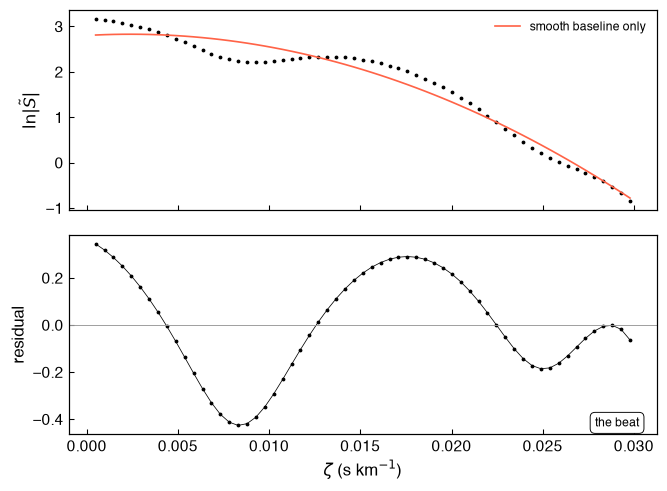

In [3]:
from specbeat import amplitude

# (1) Fit ONLY the smooth baseline [1,|zeta|,zeta^2] -- deliberately the
#     wrong (companion-free) model -- and inspect the residual.
with np.errstate(divide="ignore"):
    amp_obs, _, zeta_obs, _ = amplitude.fourier_log_amplitude(
        spec, dv, normalize_to_snr=False)
band = zeta_obs <= zeta_max
zeta_fit, log_amp_fit = zeta_obs[band], np.log(amp_obs[band])

M0 = amplitude.construct_log_amp_model_matrix(zeta_fit, 0.0,
                                              n_cos_terms=None, n_baseline=2)
w1 = np.ones_like(zeta_fit)
theta0, _, chi2_0 = amplitude.bounded_weighted_least_squares(
    M0, log_amp_fit, w1, bounds=None)
residual = log_amp_fit - M0 @ theta0

fig, axes = plt.subplots(2, 1, figsize=(6.2, 4.6), sharex=True)
axes[0].plot(zeta_fit, log_amp_fit, "k.", ms=3)
axes[0].plot(zeta_fit, M0 @ theta0, color="tomato", lw=1.1,
             label="smooth baseline only")
axes[0].set_ylabel(r"$\ln|\tilde S|$"); axes[0].legend(frameon=False)
axes[1].plot(zeta_fit, residual, "k.-", ms=3, lw=0.5)
axes[1].axhline(0, color="0.6", lw=0.6)
axes[1].set_ylabel("residual"); axes[1].set_xlabel(r"$\zeta$ (s km$^{-1}$)")
regime_label(axes[1], "the beat", loc="lower right")
fig.tight_layout()
plt.show()

In [4]:
# The residual r(zeta) ~ alpha*cos(2*pi*zeta*v) is itself a sinusoid in
# zeta. An FT over the ZETA axis therefore peaks at "frequency" v -- and
# because zeta carries s/km, that conjugate frequency carries km/s: the FT
# of a zeta-domain signal reports a VELOCITY. (Expect a ~few-km/s offset:
# the residual is not a pure sinusoid -- the baseline fit absorbed part of
# it, and the short zeta window leaks power -- so the peak shifts slightly.)
resid_pad = np.zeros(4096)
resid_pad[: len(residual)] = residual
dzeta = zeta_fit[1] - zeta_fit[0]
v_axis = np.fft.rfftfreq(len(resid_pad), d=dzeta)
v_rec = v_axis[np.argmax(np.abs(np.fft.rfft(resid_pad)))]
print(f"beat frequency of the residual = {v_rec:.1f} km/s   "
     f"(injected v = {v_true}; resolution {v_axis[1]:.1f} km/s)")

beat frequency of the residual = 58.0 km/s   (injected v = 60.0; resolution 0.5 km/s)


In [5]:
# (2) Exact vs linearized vs truth. Exact = eq. 10 at R=1 via complex
#     arithmetic (no expansion); linearized = the library's fit-model form.
def centered(x):
    return x - x.mean()

theta_beat = 2 * np.pi * zeta_fit * v_true
Ka = simulate.kernel_amp(zeta_fit, FID["vG"], FID["gamma"], FID["vsini"],
                         FID["epsilon"])

print(f"{'alpha':>6} {'RMS: exact eq.10 vs truth':>26} {'RMS: linearized vs truth':>26}")
for a in (0.05, 0.25, 0.6):
    s_a, _, _ = simulate.generate_simulated_spectrum(
        wave, dv, v=0.0, second_component=True, v2=v_true,
        vG2=FID["vG"], gamma2=FID["gamma"], vsini2=FID["vsini"],
        epsilon2=FID["epsilon"], depth_ratio=a, **FID)
    with np.errstate(divide="ignore"):
        truth = np.log(np.abs(np.fft.rfft(np.asarray(s_a, float)))[1:])[band]
    exact = np.log(Ka) + np.log(np.abs(1 + a * np.exp(-1j * theta_beat)))
    linear = simulate.binary_log_amplitude(zeta_fit, a, v_true, vG=FID["vG"],
                                           gamma=FID["gamma"], vsini=FID["vsini"],
                                           epsilon=FID["epsilon"])
    rms = lambda m: np.sqrt(np.mean((centered(m) - centered(truth)) ** 2))
    print(f"{a:>6.2f} {rms(exact):>26.2e} {rms(linear):>26.2e}")

 alpha  RMS: exact eq.10 vs truth   RMS: linearized vs truth
  0.05                   4.74e-16                   4.45e-04
  0.25                   5.29e-16                   1.14e-02
  0.60                   5.75e-16                   7.82e-02


The exact $R\equiv1$ formula matches the simulation to numerical precision at
every $\alpha$, which it should: only the delta-line limit and $R\equiv1$ enter
it, and the simulator satisfies both. What degrades is the linearized model,
accurate to $\sim10^{-3}$ at $\alpha=0.05$ and visibly off by $\alpha=0.6$. The
small-$\alpha$ assumption belongs to the fit model, not to the physics.

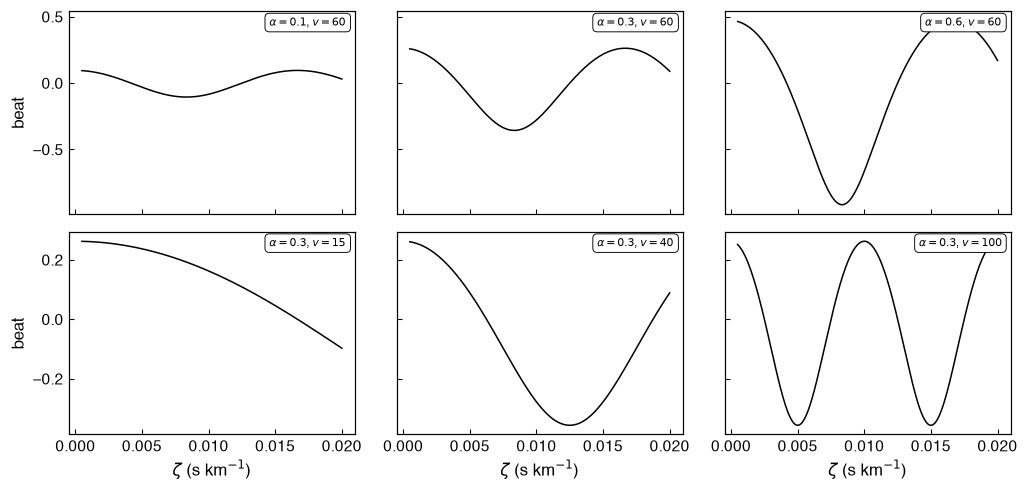

In [6]:
# (3) Beat amplitude ~ alpha (top row), beat frequency ~ v (bottom row).
zp = np.linspace(zeta_fit[0], 0.02, 300)
lnKa_p = np.log(simulate.kernel_amp(zp, FID["vG"], FID["gamma"], FID["vsini"],
                                    FID["epsilon"]))
fig, axes = plt.subplots(2, 3, figsize=(9.5, 4.6), sharex=True, sharey="row")
for ax, a in zip(axes[0], (0.1, 0.3, 0.6)):
    m = simulate.binary_log_amplitude(zp, a, 60.0, vG=FID["vG"], gamma=FID["gamma"],
                                      vsini=FID["vsini"], epsilon=FID["epsilon"])
    ax.plot(zp, m - lnKa_p, "k-", lw=1.0)
    regime_label(ax, rf"$\alpha={a}$, $v=60$", fontsize=7)
for ax, v in zip(axes[1], (15.0, 40.0, 100.0)):
    m = simulate.binary_log_amplitude(zp, 0.3, v, vG=FID["vG"], gamma=FID["gamma"],
                                      vsini=FID["vsini"], epsilon=FID["epsilon"])
    ax.plot(zp, m - lnKa_p, "k-", lw=1.0)
    regime_label(ax, rf"$\alpha=0.3$, $v={v:.0f}$", fontsize=7)
for ax in axes[:, 0]: ax.set_ylabel("beat")
for ax in axes[1]: ax.set_xlabel(r"$\zeta$ (s km$^{-1}$)")
fig.tight_layout()
plt.show()

### Breaking $\mathcal R(\zeta) \equiv 1$

$\mathcal R$ is the ratio of the two components' Fourier kernels. Below are two
cases, both fitted with the same $R\equiv1$ model.

In case A the kernels are identical — the fiducial pair — so $\mathcal R \equiv 1$
exactly. In case B the primary rotates fast ($v\sin i = 100$) and the companion
is narrow ($v\sin i = 10$); the primary's kernel decays faster in $\zeta$, so
$\mathcal R$ grows across the band. That is the least favourable configuration
in App. D, and it is where the real CPD$-$41°7742 sits.

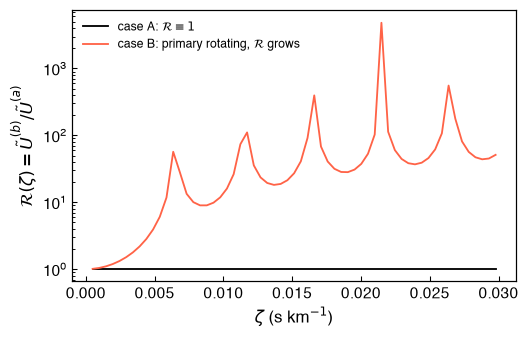

case B: R rises from 1.01 to 51.2 across the fit band


In [7]:
# (4a) R(zeta) itself -- the cause, before the symptom.
Ka_A = simulate.kernel_amp(zeta_fit, FID["vG"], FID["gamma"], 20.0, 0.5)
Kb_A = Ka_A                                                # identical kernels
Ka_B = simulate.kernel_amp(zeta_fit, FID["vG"], FID["gamma"], 100.0, 0.5)
Kb_B = simulate.kernel_amp(zeta_fit, FID["vG"], FID["gamma"], 10.0, 0.5)

fig, ax = plt.subplots(figsize=(5.2, 3.2))
ax.semilogy(zeta_fit, Kb_A / Ka_A, "k-", label=r"case A: $\mathcal{R}\equiv 1$")
ax.semilogy(zeta_fit, Kb_B / Ka_B, "-", color="tomato",
            label=r"case B: primary rotating, $\mathcal{R}$ grows")
ax.set_xlabel(r"$\zeta$ (s km$^{-1}$)")
ax.set_ylabel(r"$\mathcal{R}(\zeta) = \tilde U^{(b)}/\tilde U^{(a)}$")
ax.legend(frameon=False, loc="upper left")
plt.show()
print(f"case B: R rises from {float((Kb_B/Ka_B)[0]):.2f} to "
     f"{float((Kb_B/Ka_B)[-1]):.1f} across the fit band")

case A (R=1):   chi2 =   0.312   alpha_hat = 0.309  (true 0.3)
case B (R!=1):  chi2 =   7.975   alpha_hat = 0.213  (true 0.3)


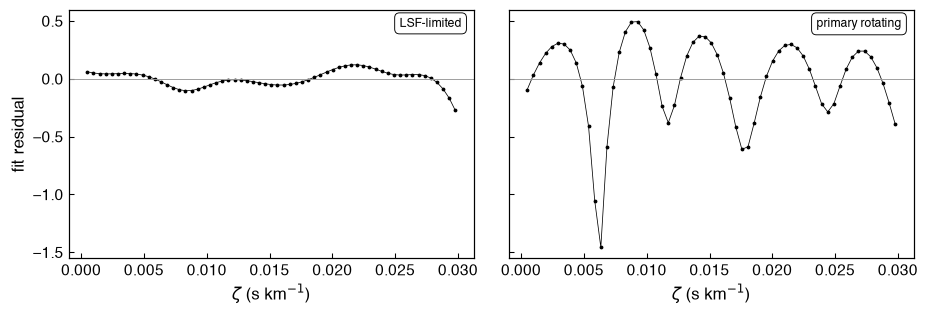

In [8]:
# (4b) The same R=1 fit model applied to both cases, at the true v.
def fit_R1(spec_arr):
    with np.errstate(divide="ignore"):
        a_, _, z_, _ = amplitude.fourier_log_amplitude(spec_arr, dv,
                                                       normalize_to_snr=False)
    b = z_ <= zeta_max
    zf, lf = z_[b], np.log(a_[b])
    M = amplitude.construct_log_amp_model_matrix(zf, v_true, n_cos_terms=0,
                                                 n_baseline=2)
    th, _, c2 = amplitude.bounded_weighted_least_squares(M, lf, np.ones_like(zf),
                                                         bounds=None)
    return zf, lf - M @ th, c2, th[-1]

spec_A, _, _ = simulate.generate_simulated_spectrum(
    wave, dv, v=0.0, second_component=True, v2=v_true, vG2=FID["vG"],
    gamma2=FID["gamma"], vsini2=20.0, epsilon2=0.5, depth_ratio=alpha_true, **FID)
spec_B, _, _ = simulate.generate_simulated_spectrum(
    wave, dv, v=0.0, second_component=True, v2=v_true, vG2=FID["vG"],
    gamma2=FID["gamma"], vsini2=10.0, epsilon2=0.5, depth_ratio=alpha_true,
    **{**FID, "vsini": 100.0})

zA, rA, c2A, aA = fit_R1(np.asarray(spec_A, float))
zB, rB, c2B, aB = fit_R1(np.asarray(spec_B, float))
print(f"case A (R=1):   chi2 = {c2A:7.3f}   alpha_hat = {aA:.3f}  (true {alpha_true})")
print(f"case B (R!=1):  chi2 = {c2B:7.3f}   alpha_hat = {aB:.3f}  (true {alpha_true})")

fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.0), sharey=True)
axes[0].plot(zA, rA, "k.-", ms=3, lw=0.5)
axes[1].plot(zB, rB, "k.-", ms=3, lw=0.5)
for ax in axes:
    ax.axhline(0, color="0.6", lw=0.6)
    ax.set_xlabel(r"$\zeta$ (s km$^{-1}$)")
axes[0].set_ylabel("fit residual")
regime_label(axes[0], "LSF-limited", loc="upper right")
regime_label(axes[1], "primary rotating", loc="upper right")
fig.tight_layout()
plt.show()

Same injected $\alpha$ and the same model, but case B's $\chi^2$ inflates by an
order of magnitude, its residual is structured rather than noise-like, and
$\hat\alpha$ comes out low. That residual structure is the diagnostic: it is how
you find out that $R\equiv1$ is failing, and it is why the paper's worked
example reports a systematic 16–24% spread in $\hat\alpha$ between channels
(§4.3). The polynomial kernel-ratio correction of App. D is the `n_cos_terms > 0`
option in `construct_log_amp_model_matrix`, which this version of the package
does not use.

If your two components have visibly different broadening, expect case-B
behaviour, and inspect the fit residual for structure before trusting
$\hat\alpha$. The velocity scan of notebook 3 reuses exactly this fit at each
trial $v$; nothing new is introduced there.

So the companion is a beat, with amplitude $\alpha$ and frequency $v$ (eq. 12).
The exact $R\equiv1$ log-amplitude is essentially perfect. Linearization in
$\alpha$ is the approximation that matters for the fit, and kernel inequality is
the assumption that fails on real unequal pairs — visibly, in the residual.

## The phase channel

The amplitude channel throws away the phase, and the phase is where the velocity
information was. Shift each epoch into the primary's rest frame and it comes
back (eq. 13); linearizing gives the phase model (eq. 14):

$$\ln\tilde S_0 \approx \ln|\tilde S| - i\,\alpha\,\mathcal R(\zeta)\sin(2\pi\zeta v),
\qquad
z_i \equiv \arg\tilde S_{0,i} = -b_0\sin(2\pi\zeta_i b_1) + n_i,$$

with $b_0 \to \alpha$ and $b_1 \to v$. Unlike eq. 12 there is no nuisance
baseline at all: under $H_0$ the observable is simply zero. The exact phase at
$R\equiv1$ is $z = \arg(1+\alpha e^{-i2\pi\zeta v})$, and eq. 14 is its first
order in $\alpha$.

This assumes the primary rest frame is known, from an ephemeris or a separate RV
fit, and the demonstrations below quantify what a wrong one costs. It also
assumes $\mathcal R \equiv 1$ and small $\alpha$, as before. Near-twin systems
are outside its reach for a different reason: with $\alpha$ close to 1 the idea
of a unique primary rest frame degenerates, and those need two-template
modelling rather than this test.

What follows: $z(\zeta)$ built by hand from the composite FFT and checked
against the exact $\arg(1+\alpha e^{-i\theta})$, with $-\alpha\sin\theta$ as its
small-$\alpha$ tangent; a fit for $\alpha$ under noise using the library's
closed-form likelihood-ratio test; the odd/even symmetry that distinguishes the
two channels; and the cost of getting the rest frame wrong.

check: by-hand z = library phase_observable: True
check: z = exact arg(1 + alpha e^{-i theta}): True
max |z - linearized model| = 0.0525  (the O(alpha^2) term at alpha = 0.3)


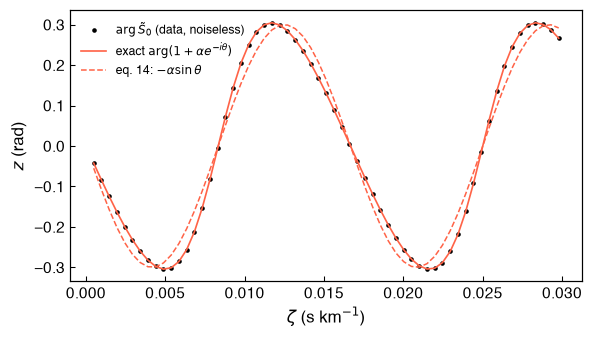

In [9]:
from specbeat import phase

# The line center sits at pixel-position x0 (in velocity units) on this
# grid; the rest-frame shift must include it. With primary velocity v_a = 0,
# rest_shift = x0.
x0 = np.interp(FID["wavelength_0"], wave, np.arange(N)) * dv

alpha_ph, v_ph = 0.3, 60.0
spec_ph, _, _ = simulate.generate_simulated_spectrum(
    wave, dv, v=0.0, second_component=True, v2=v_ph, vG2=FID["vG"],
    gamma2=FID["gamma"], vsini2=FID["vsini"], epsilon2=FID["epsilon"],
    depth_ratio=alpha_ph, **FID)
spec_ph = np.asarray(spec_ph, float)

zeta_all = np.fft.rfftfreq(N, d=dv)[1:]
band_ph = zeta_all <= zeta_max
zeta_p = zeta_all[band_ph]
ft_p = np.fft.rfft(spec_ph)[1:][band_ph]

# (1) by hand: S0 = -fft * exp(+2*pi*i*zeta*x0); z = arg(S0). The minus sign
#     puts H0 on the +real axis (off the np.angle branch cut).
z_hand = np.angle(-ft_p * np.exp(2j * np.pi * zeta_p * x0))
theta_p = 2 * np.pi * zeta_p * v_ph
z_exact = np.angle(1 + alpha_ph * np.exp(-1j * theta_p))
z_lin = -alpha_ph * np.sin(theta_p)

z_lib, _ = phase.phase_observable(ft_p, zeta_p, rest_shift_kms=x0, sigma_ft=1.0)
print("check: by-hand z = library phase_observable:",
     np.allclose(z_hand, z_lib, atol=1e-12))
print("check: z = exact arg(1 + alpha e^{-i theta}):",
     np.allclose(z_hand, z_exact, atol=1e-9))
print(f"max |z - linearized model| = {np.max(np.abs(z_hand - z_lin)):.4f}"
     f"  (the O(alpha^2) term at alpha = {alpha_ph})")

fig, ax = plt.subplots(figsize=(6.0, 3.2))
ax.plot(zeta_p, z_hand, "k.", ms=4, label=r"$\arg\tilde S_0$ (data, noiseless)")
ax.plot(zeta_p, z_exact, "-", color="tomato", lw=1.1,
        label=r"exact $\arg(1+\alpha e^{-i\theta})$")
ax.plot(zeta_p, z_lin, "--", color="tomato", lw=1.0,
        label=r"eq. 14: $-\alpha\sin\theta$")
ax.set_xlabel(r"$\zeta$ (s km$^{-1}$)"); ax.set_ylabel(r"$z$ (rad)")
ax.legend(frameon=False)
plt.show()

In [10]:
from specbeat import amplitude as amp_mod

# (2) fit alpha under noise (fiducial sigma_pix = 0.01), library LRT.
sigma_pix = 0.01
spec_noisy = spec_ph + rng.normal(0.0, sigma_pix, N)
ft_noisy = np.fft.rfft(spec_noisy)[1:][band_ph]
sigma_ft = amp_mod.amp_noise_sigma(sigma_pix, n=N)

fit = phase.fit_phase_alpha(ft_noisy, zeta_p, rest_shift_kms=x0, dv_rel=v_ph,
                            sigma_ft=sigma_ft)
print(f"alpha_hat = {fit['alpha_hat']:.3f} +/- {fit['sigma_alpha']:.4f}"
     f"   (true {alpha_ph});   T = {fit['T']:.0f}")

alpha_hat = 0.291 +/- 0.0053   (true 0.3);   T = 2972


In [11]:
# (3) symmetry: inject the companion at +50 then -50 km/s.
rows = {}
for v_test in (+50.0, -50.0):
    s, _, _ = simulate.generate_simulated_spectrum(
        wave, dv, v=0.0, second_component=True, v2=v_test, vG2=FID["vG"],
        gamma2=FID["gamma"], vsini2=FID["vsini"], epsilon2=FID["epsilon"],
        depth_ratio=0.25, **FID)
    s = np.asarray(s, float)
    a_s = np.abs(np.fft.rfft(s))[1:][band_ph]
    z_s, _ = phase.phase_observable(np.fft.rfft(s)[1:][band_ph], zeta_p,
                                    rest_shift_kms=x0, sigma_ft=1.0)
    rows[v_test] = (a_s.mean(), z_s[5])

print(f"{'v (km/s)':>9} {'mean |S~|  (amplitude channel)':>31} {'z at zeta[5]  (phase channel)':>30}")
for v_test, (a, z) in rows.items():
    print(f"{v_test:>+9.0f} {a:>31.6f} {z:>30.4f}")
print("\namplitude: EVEN in v (cos) -- blind to the companion's side.")
print("phase:     ODD  in v (sin) -- carries the sign.")

 v (km/s)  mean |S~|  (amplitude channel)  z at zeta[5]  (phase channel)
      +50                        8.486325                        -0.1711
      -50                        8.486325                         0.1711

amplitude: EVEN in v (cos) -- blind to the companion's side.
phase:     ODD  in v (sin) -- carries the sign.


In [12]:
# (4) the cost: a rest-frame error delta_v on a SINGLE-STAR spectrum
#     (no companion at all) produces a phase ramp that fits as a fake
#     companion. Threshold for reference: T = 2.706 (notebook 03).
spec_1, _, _ = simulate.generate_simulated_spectrum(
    wave, dv, v=0.0, second_component=False, **FID)
spec_1 = np.asarray(spec_1, float) + rng.normal(0.0, sigma_pix, N)
ft_1 = np.fft.rfft(spec_1)[1:][band_ph]

print(f"{'RV error (km/s)':>16} {'fake alpha_hat':>15} {'T':>9} {'sigma':>7}")
for dv_err in (0.0, 1.0, 2.0, 5.0, 10.0):
    f = phase.fit_phase_alpha(ft_1, zeta_p, rest_shift_kms=x0 + dv_err,
                              dv_rel=60.0, sigma_ft=sigma_ft)
    print(f"{dv_err:>16.1f} {f['alpha_hat']:>+15.4f} {f['T']:>9.1f} "
         f"{f['significance']:>7.2f}")

 RV error (km/s)  fake alpha_hat         T   sigma
             0.0         -0.0002       0.0    0.03
             1.0         -0.0037       0.4    0.66
             2.0         -0.0072       1.6    1.28
             5.0         -0.0177      10.1    3.17
            10.0         -0.0353      39.9    6.31


A 5–10 km/s rest-frame error on a companion-free spectrum manufactures a
formally significant detection. The paper's requirement that the primary
velocity be known to better than $\sim\alpha v$ is the operational cost of the
phase channel.

In practice, measure `rest_shift_kms` from your own data — from an isolated
primary-only line, as the paper does with He II — and propagate its uncertainty,
checking it against $\sim\alpha v$. It is worth verifying the sign convention on
a known-single spectrum first: $z$ should sit near zero across the band, as in
the $\delta v = 0$ row above. A sign error puts $z$ on the $\pm\pi$ branch cut,
where it is obvious once you know to look.

The phase channel, then, is $z=-\alpha\sin(2\pi\zeta v)$: no baseline, and odd
in $v$. It responds to profile asymmetry, which a single star cannot fake, and
it pays for that sensitivity with an externally known rest frame.

Next: [`03_detection_and_calibration.ipynb`](03_detection_and_calibration.ipynb).